# H1: Does rs3184504 Genotype Affect Vessel Density in Follicles?

**Rationale:** SH2B3 loss-of-function (rs3184504 T allele) promotes endothelial
progenitor mobilization via JAK-STAT de-repression. If the T allele increases
splenic vascularization, the effect should be most detectable in follicles —
discrete white-pulp structures where immune signaling is concentrated.

**Design:** 13 samples (8 Phenocycler, 5 CODEX), 3 genotype groups (C/C=4, C/T=6, T/T=3).

**Unit of analysis:** Individual follicle region annotations (pixel-classifier output,
not biological follicles). SmallVessels are assigned to their nearest annotation
centroid via cKDTree, then density (vessels/mm²) is computed per annotation.
Linear mixed-effects models with Sample as random intercept account for
within-image correlation and unequal annotation counts across images.

**Additionally:** Vessel density stratified by vessel size (area tertiles), and
comprehensive vessel morphology analysis (area, circularity, solidity, elongation)
across all tissue regions.

> **Caveat:** n=3–4 samples per group; results are exploratory.
> CODEX vs Phenocycler platform confound is assessed explicitly.

In [1]:
import sys
sys.path.insert(0, '.')
from data_utils import *
from data_utils import (
    _CODEX_CLASS_MAP, _CODEX_REGION_MAP, GENOTYPE_MAP,
)
import statsmodels.formula.api as smf
setup_style()

## Data Loading Functions

`compute_per_region_density` is defined here because it is specific to this
notebook (per-annotation follicle density, vessels assigned by cKDTree).

`load_all_data` is **imported** from `data_utils`, not redefined. It used to be
overridden here for inspection, but that copy drifted from the library and
hardcoded `Platform = "Phenocycler"`, which mislabelled the two CODEX samples
carried in `AnnotationsFinal.csv` (1901HBMP004, HDL073).


In [2]:
def compute_per_region_density(df: pd.DataFrame, region_layer=None) -> pd.DataFrame:
    """Compute vessel density per follicle region annotation.

    Each row in the output is one Follicle-classified annotation (a contiguous
    patch of follicle tissue from the pixel classifier — NOT an individual
    biological follicle). A SmallVessel counts as follicular when its centroid
    falls inside a Follicle polygon of the region layer; it is then assigned to
    its nearest annotation centroid via cKDTree.

    Region membership used to be read off QuPath's `Parent` string. That is
    what made 1901HBMP004 report zero vessels in 35 Follicle annotations — its
    hierarchy pass failed and stranded 21.5% of its SmallVessels at the image
    root. Point-in-polygon does not depend on the hierarchy.

    Returns DataFrame with one row per annotation:
      Image, Sample, Genotype, Platform, Object_ID,
      Region_Area_um2, Region_Area_mm2, Vessel_Count, Density_per_mm2
    """
    from scipy.spatial import cKDTree

    if region_layer is None:
        region_layer = load_region_layer()

    records = []
    for image in df['Image'].unique():
        img_df = df[df['Image'] == image]
        sample = img_df['Sample'].iloc[0]
        genotype = str(img_df['Genotype'].iloc[0])
        platform = 'CODEX' if sample in CODEX_SAMPLES else 'Phenocycler'

        # Follicle region annotations
        regions = img_df[img_df['Classification'] == 'Follicle'].copy()
        if regions.empty:
            continue

        reg_coords = regions[['Centroid X µm', 'Centroid Y µm']].values
        reg_ids = regions['Object ID'].values
        reg_areas = regions['Area µm^2'].values

        # SmallVessels inside a Follicle polygon of the region layer
        vessels = get_vessels(img_df, region_layer=region_layer)
        vessels = vessels[vessels['Region'] == 'Follicle']

        # Assign vessels to nearest region annotation centroid
        vessel_counts = np.zeros(len(regions), dtype=int)
        if not vessels.empty:
            tree = cKDTree(reg_coords)
            ves_coords = vessels[['Centroid X µm', 'Centroid Y µm']].values
            _, indices = tree.query(ves_coords)
            for idx in indices:
                vessel_counts[idx] += 1

        for i in range(len(regions)):
            area_mm2 = reg_areas[i] / 1e6
            records.append({
                'Image': image,
                'Sample': sample,
                'Genotype': genotype,
                'Platform': platform,
                'Object_ID': reg_ids[i],
                'Region_Area_um2': reg_areas[i],
                'Region_Area_mm2': area_mm2,
                'Vessel_Count': vessel_counts[i],
                'Density_per_mm2': vessel_counts[i] / area_mm2,
            })

    result = pd.DataFrame(records)
    result['Genotype'] = pd.Categorical(
        result['Genotype'], categories=GENO_ORDER, ordered=True)
    return result

In [3]:
df = load_all_data()

# The region layer is ~130 MB of GeoJSON, so load it once and pass it down.
region_layer = load_region_layer()
fol_per = compute_per_region_density(df, region_layer=region_layer)

# Also compute per-image aggregated density for reference
density = compute_density(df, region_layer=region_layer)
density['Platform'] = density['Sample'].apply(
    lambda s: 'CODEX' if s in CODEX_SAMPLES else 'Phenocycler')
fol_img = density[density['Region'] == 'Follicle'].copy()
fol_img_pc = fol_img[fol_img['Platform'] == 'Phenocycler'].copy()

# Per-annotation subsets
fol_pc = fol_per[fol_per['Platform'] == 'Phenocycler'].copy()

print(f'Per-annotation observations: {len(fol_per)} follicle region annotations '
      f'across {fol_per["Sample"].nunique()} samples')
print(f'  Phenocycler: {len(fol_pc)} annotations, {fol_pc["Sample"].nunique()} samples')
print(f'  CODEX: {len(fol_per) - len(fol_pc)} annotations, '
      f'{fol_per["Sample"].nunique() - fol_pc["Sample"].nunique()} samples')
print(f'\nAnnotations per genotype:')
print(fol_per.groupby('Genotype', observed=True).agg(
    n_annotations=('Object_ID', 'count'),
    n_samples=('Sample', 'nunique'),
    median_density=('Density_per_mm2', 'median'),
).to_string())

# --- Data-integrity check: vessels that no region polygon contains -----------
# The old check here counted Follicle annotations whose QuPath `Parent` pass had
# failed, because a broken hierarchy made density evaluate to 0 instead of being
# flagged. Point-in-polygon assignment cannot fail that way, so that check no
# longer measures anything.
#
# The failure mode that remains is a vessel outside every region polygon — the
# region layer clips to a tissue mask derived from cell density, so a vessel in
# tissue the mask missed lands nowhere. That is a real exclusion and it should
# be visible, not silent.
_sv = get_vessels(df, region_layer=region_layer)
_unassigned = (_sv['Region'].eq('Unassigned')
               .groupby(_sv['Sample'], observed=True).mean().mul(100).round(1))
# Cohort-wide this runs 4-9%: vessels sitting just outside the KDE tissue
# contour, concentrated at section edges. 10% is the line above which it stops
# looking like an edge effect and starts looking like a bad mask.
print(f'\nSmallVessels outside every region polygon, by sample '
      f'(median {_unassigned.median():.1f}%):')
print('    ' + ', '.join(f'{_s} {_p}%' for _s, _p in _unassigned.sort_values(
    ascending=False).items()))
_bad = _unassigned[_unassigned > 10.0]
if len(_bad):
    print('\nWARNING - >10% unassigned, check the tissue mask for: '
          + ', '.join(_bad.index))

_zero = [(_s, len(_g)) for _s, _g in fol_per.groupby('Sample', observed=True)
         if len(_g) > 0 and _g['Vessel_Count'].sum() == 0]
if _zero:
    print('\nWARNING - samples with Follicle annotations but no follicular vessels:')
    for _s, _n in _zero:
        print(f'    {_s}: {_n} Follicle annotations, 0 vessels')

Per-annotation observations: 2169 follicle region annotations across 14 samples
  Phenocycler: 1928 annotations, 9 samples
  CODEX: 241 annotations, 5 samples

Annotations per genotype:
          n_annotations  n_samples  median_density
Genotype                                          
C/C                 763          4      211.157566
C/T                 896          7       86.978249
T/T                 510          3       68.521550



SmallVessels outside every region polygon, by sample (median 3.9%):
    HDL052 9.4%, HDL011 8.6%, HDL055 8.3%, HDL073 5.1%, HDL043 4.6%, HBMP007 4.5%, HDL098 4.0%, HDL070 3.7%, HDL053 3.5%, 1901HBMP004 3.5%, HBMP006 3.4%, HDL086 3.0%, HDL063 2.2%, HDL079 2.2%


## Figure 1: Follicle Regions Across All Images

Binary map showing follicle annotation footprints (circles scaled by area at centroid position).
Each panel is one image, grouped by genotype.

Saved: analysis/figures/H1_follicle_binary_map.png


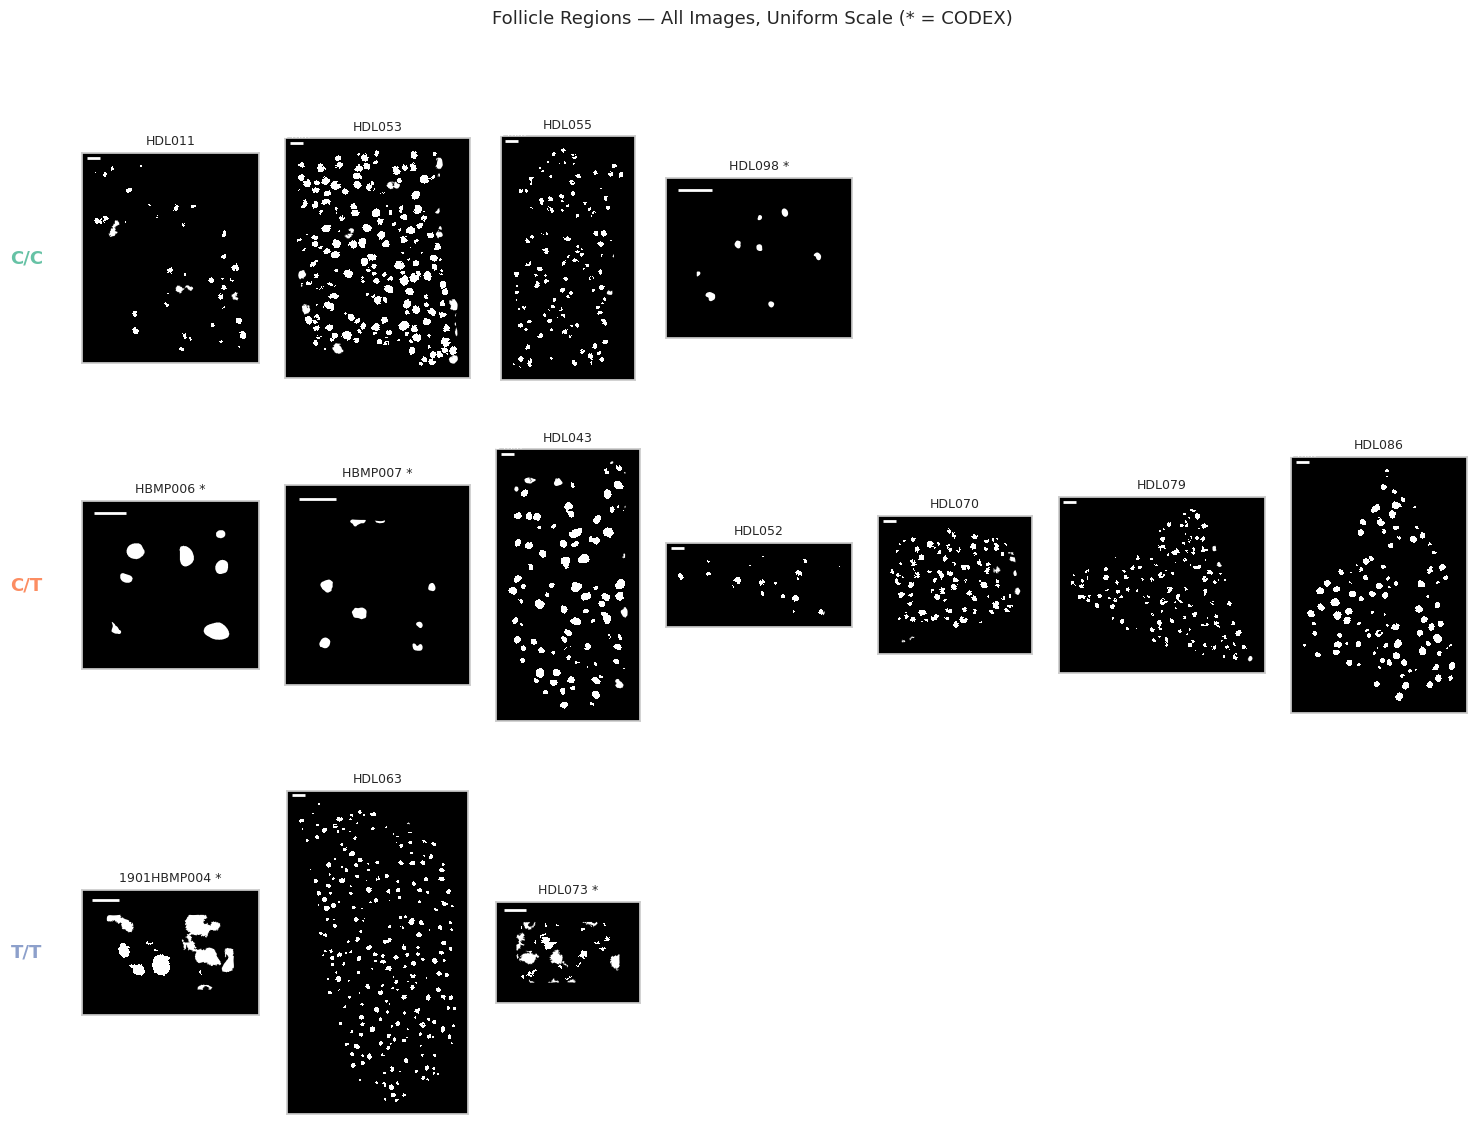

Follicle polygons drawn, from the region layer:
  1901HBMP004             10 follicles  0.3740 um/px  (CODEX)
  HBMP006                  7 follicles  0.3774 um/px  (CODEX)
  HBMP007                  8 follicles  0.3774 um/px  (CODEX)
  HDL011                  39 follicles  0.5078 um/px  (Phenocycler)
  HDL018                  24 follicles  0.5078 um/px  (Phenocycler)
  HDL021                 109 follicles  0.5078 um/px  (Phenocycler)
  HDL043                  91 follicles  0.5078 um/px  (Phenocycler)
  HDL052                  20 follicles  0.5078 um/px  (Phenocycler)
  HDL053                 190 follicles  0.5078 um/px  (Phenocycler)
  HDL055                 120 follicles  0.5078 um/px  (Phenocycler)
  HDL063                 240 follicles  0.5078 um/px  (Phenocycler)
  HDL070                  90 follicles  0.5078 um/px  (Phenocycler)
  HDL073                  28 follicles  0.3740 um/px  (CODEX)
  HDL079                 127 follicles  0.5078 um/px  (Phenocycler)
  HDL086                

In [4]:
import json, glob, os
from matplotlib.patches import Polygon as MplPolygon
from matplotlib.collections import PatchCollection
from matplotlib.gridspec import GridSpec

# --- Follicle outlines come from the region layer -------------------------
# Previously this cell re-read analysis/geojson/ (the superseded Follicle+PALS
# export) and rescaled pixels with a two-value pixel-size table. That table was
# wrong for 1901HBMP004 and HDL073, whose OME-XML declares 0.5078 but which are
# really 0.374 — see data_utils.get_pixel_size. The region layer is already in
# µm and already carries the area floor, so none of that is needed here.
polygon_layer = {extract_sample_id(stem): regions
                 for stem, regions in region_layer.items()}

def load_follicle_polygons(sid):
    """Return list of (N,2) arrays of follicle vertices in µm."""
    polys = []
    for poly in polygon_layer.get(sid, {}).get('Follicle', []):
        polys.append(np.asarray(poly.exterior.coords))
    return polys

# --- Gather per-sample polygon data ---
follicles_csv = df[df['Classification'] == 'Follicle'].copy()
follicles_csv['Sample'] = follicles_csv['Image'].apply(extract_sample_id)
follicles_csv['Genotype'] = follicles_csv['Sample'].map(GENOTYPE_MAP)
follicles_csv['Platform'] = follicles_csv['Sample'].apply(
    lambda s: 'CODEX' if s in CODEX_SAMPLES else 'Phenocycler')

sample_meta = (follicles_csv.drop_duplicates('Sample')[['Sample', 'Genotype', 'Platform']]
               .sort_values(['Genotype', 'Sample']))

# Load all polygon data and compute extents in µm
sample_data = {}
for _, row in sample_meta.iterrows():
    sid = row['Sample']
    polys = load_follicle_polygons(sid)
    if polys:
        all_x = np.concatenate([p[:, 0] for p in polys])
        all_y = np.concatenate([p[:, 1] for p in polys])
    else:
        sf = follicles_csv[follicles_csv['Sample'] == sid]
        polys = None
        all_x = sf['Centroid X µm'].values
        all_y = sf['Centroid Y µm'].values
    sample_data[sid] = {
        'polys': polys, 'geno': str(row['Genotype']), 'plat': row['Platform'],
        'xmin': all_x.min(), 'xmax': all_x.max(),
        'ymin': all_y.min(), 'ymax': all_y.max(),
        'width': all_x.max() - all_x.min(),
        'height': all_y.max() - all_y.min(),
    }

# --- Uniform scale: compute global µm-per-inch ---
INCHES_PER_PANEL_MAX = 4.0
global_max_extent = max(max(d['width'], d['height']) for d in sample_data.values())
um_per_inch = global_max_extent / INCHES_PER_PANEL_MAX  # all panels use this scale
pad_um = global_max_extent * 0.04  # uniform padding

# --- Layout: one row per genotype, panel sizes proportional to tissue extent ---
geno_samples = {}
for _, row in sample_meta.iterrows():
    geno_samples.setdefault(str(row['Genotype']), []).append(row['Sample'])

max_per_row = max(len(v) for v in geno_samples.values())

# Compute panel sizes in inches for GridSpec
all_widths = []  # per column, take max across rows
for col_idx in range(max_per_row):
    col_widths = []
    for geno in GENO_ORDER:
        sids = geno_samples.get(geno, [])
        if col_idx < len(sids):
            d = sample_data[sids[col_idx]]
            col_widths.append((d['width'] + 2 * pad_um) / um_per_inch)
    all_widths.append(max(col_widths) if col_widths else 1.0)

all_heights = []  # per row, take max
for geno in GENO_ORDER:
    sids = geno_samples.get(geno, [])
    row_heights = []
    for sid in sids:
        d = sample_data[sid]
        row_heights.append((d['height'] + 2 * pad_um) / um_per_inch)
    all_heights.append(max(row_heights) if row_heights else 1.0)

fig_w = sum(all_widths) + 1.5  # extra for labels
fig_h = sum(all_heights) + 1.5

fig = plt.figure(figsize=(fig_w, fig_h))
gs = GridSpec(len(GENO_ORDER), max_per_row, figure=fig,
              width_ratios=all_widths, height_ratios=all_heights,
              wspace=0.15, hspace=0.25)

for row_idx, geno in enumerate(GENO_ORDER):
    samples_in_geno = geno_samples.get(geno, [])
    for col_idx in range(max_per_row):
        ax = fig.add_subplot(gs[row_idx, col_idx])
        if col_idx >= len(samples_in_geno):
            ax.set_visible(False)
            continue

        sid = samples_in_geno[col_idx]
        d = sample_data[sid]

        # Draw polygons
        patches = []
        if d['polys']:
            for coords in d['polys']:
                patches.append(MplPolygon(coords[:, :2], closed=True))
        else:
            sf = follicles_csv[follicles_csv['Sample'] == sid]
            from matplotlib.patches import Circle
            for _, r in sf.iterrows():
                radius = np.sqrt(r['Area µm^2'] / np.pi)
                patches.append(Circle((r['Centroid X µm'], r['Centroid Y µm']), radius))

        pc = PatchCollection(patches, facecolor='white', edgecolor='none')
        ax.add_collection(pc)

        # Uniform scale: center data in panel
        cx = (d['xmin'] + d['xmax']) / 2
        cy = (d['ymin'] + d['ymax']) / 2
        half_w = (d['width'] / 2) + pad_um
        half_h = (d['height'] / 2) + pad_um
        ax.set_xlim(cx - half_w, cx + half_w)
        ax.set_ylim(cy + half_h, cy - half_h)  # invert Y

        ax.set_facecolor('black')
        ax.set_aspect('equal')
        plat_tag = ' *' if d['plat'] == 'CODEX' else ''
        ax.set_title(f'{sid}{plat_tag}', fontsize=9)
        ax.set_xticks([])
        ax.set_yticks([])

        # Scale bar: 1 mm on every panel
        bar_len = 1000  # µm
        x_lo, x_hi = ax.get_xlim()
        _, y_hi = ax.get_ylim()  # y_hi is bottom (inverted)
        bar_x = x_lo + pad_um * 0.4
        bar_y = y_hi + pad_um * 0.4
        ax.plot([bar_x, bar_x + bar_len], [bar_y, bar_y],
                'w-', linewidth=2, solid_capstyle='butt')
        ax.text(bar_x + bar_len / 2, bar_y - pad_um * 0.5, '1 mm',
                color='white', ha='center', fontsize=7)

    # Row label
    first_ax = fig.axes[row_idx * max_per_row]
    first_ax.set_ylabel(geno, fontsize=13, fontweight='bold',
                        color=GENO_PALETTE[geno], rotation=0,
                        labelpad=40, va='center')

fig.suptitle('Follicle Regions — All Images, Uniform Scale (* = CODEX)', fontsize=13, y=0.98)
save_figure(fig, 'H1_follicle_binary_map')
plt.show()

# Provenance: what the region layer supplied, and the pixel size that built it.
print('Follicle polygons drawn, from the region layer:')
for sid in sorted(polygon_layer):
    n = len(polygon_layer[sid].get('Follicle', []))
    print(f'  {sid:20s}  {n:4d} follicles  {get_pixel_size(sid):.4f} um/px  '
          f'({"CODEX" if sid in CODEX_SAMPLES else "Phenocycler"})')


## Figure 2: Vessel Density per Follicle Region Annotation

Each point is one follicle region annotation (pixel-classifier output, not a biological follicle).
Violin shows the density distribution within each genotype group.

/tmp/ipykernel_1592312/4015000161.py:7: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=fol_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,


Saved: analysis/figures/H1_follicle_density_per_annotation.png


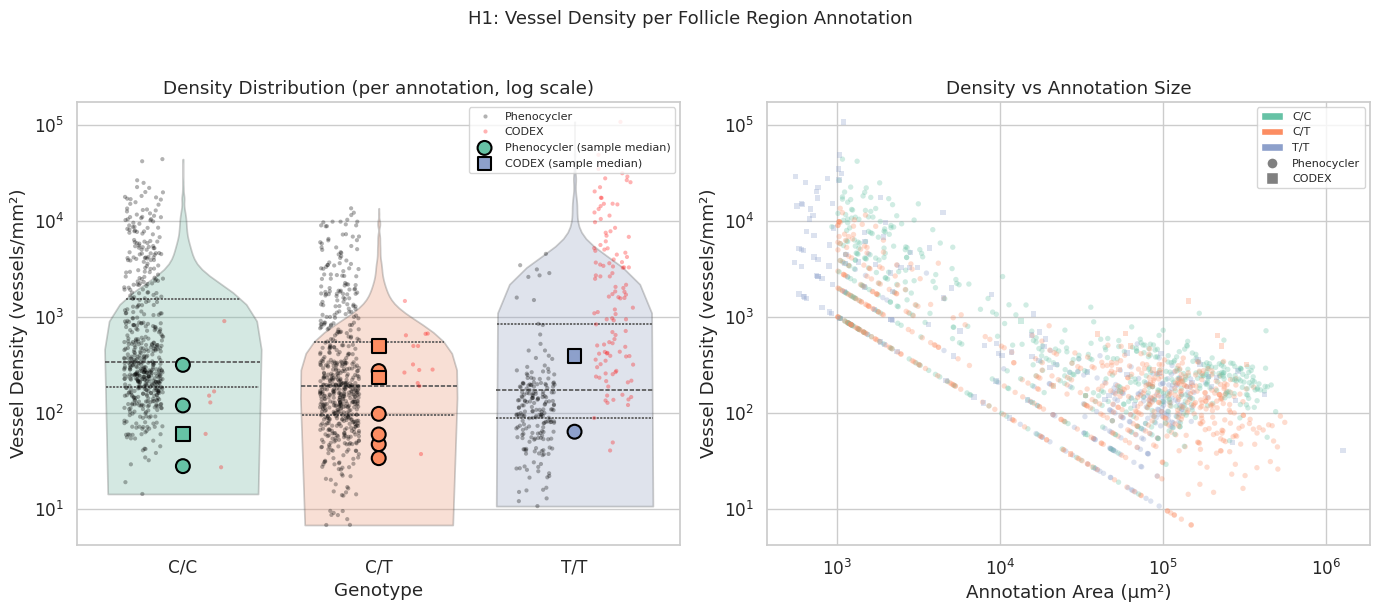

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
markers = {'Phenocycler': 'o', 'CODEX': 's'}

# Left: violin + strip by genotype (log scale, exclude zeros)
ax = axes[0]
fol_plot = fol_per[fol_per['Density_per_mm2'] > 0]
sns.violinplot(data=fol_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
               palette=GENO_PALETTE, inner='quartile', alpha=0.3, ax=ax, cut=0)
sns.stripplot(data=fol_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
              hue='Platform', palette={'Phenocycler': 'black', 'CODEX': 'red'},
              dodge=True, alpha=0.3, size=3, ax=ax, jitter=0.2)
# Overlay per-sample medians
sample_med = fol_per.groupby(['Sample', 'Genotype', 'Platform'], observed=True)['Density_per_mm2'].median().reset_index()
for plat, mkr in markers.items():
    sub = sample_med[sample_med['Platform'] == plat]
    x_pos = sub['Genotype'].astype(str).map({g: i for i, g in enumerate(GENO_ORDER)})
    ax.scatter(x_pos, sub['Density_per_mm2'], marker=mkr, s=100,
               c=[GENO_PALETTE[g] for g in sub['Genotype']], edgecolors='black',
               linewidths=1.5, zorder=10, label=f'{plat} (sample median)')
ax.set_yscale('log')
ax.set_ylabel('Vessel Density (vessels/mm²)')
ax.set_title('Density Distribution (per annotation, log scale)')
ax.legend(fontsize=8, loc='upper right')

# Right: annotation area vs density scatter (log-log)
ax = axes[1]
for plat, mkr in markers.items():
    sub = fol_per[fol_per['Platform'] == plat]
    ax.scatter(sub['Region_Area_um2'], sub['Density_per_mm2'],
               c=[GENO_PALETTE[g] for g in sub['Genotype']],
               marker=mkr, alpha=0.3, s=15, edgecolors='none')
ax.set_xscale('log')
ax.set_yscale('log')
ax.set_xlabel('Annotation Area (µm²)')
ax.set_ylabel('Vessel Density (vessels/mm²)')
ax.set_title('Density vs Annotation Size')
from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=GENO_PALETTE[g], label=g) for g in GENO_ORDER]
legend_elements += [plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='gray',
                               label='Phenocycler', markersize=8),
                    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='gray',
                               label='CODEX', markersize=8)]
ax.legend(handles=legend_elements, fontsize=8, loc='upper right')

fig.suptitle('H1: Vessel Density per Follicle Region Annotation', fontsize=13, y=1.02)
fig.tight_layout()
save_figure(fig, 'H1_follicle_density_per_annotation')
plt.show()

## Figure 3: Per-Sample Median Follicle Density

Saved: analysis/figures/H1_follicle_per_sample.png


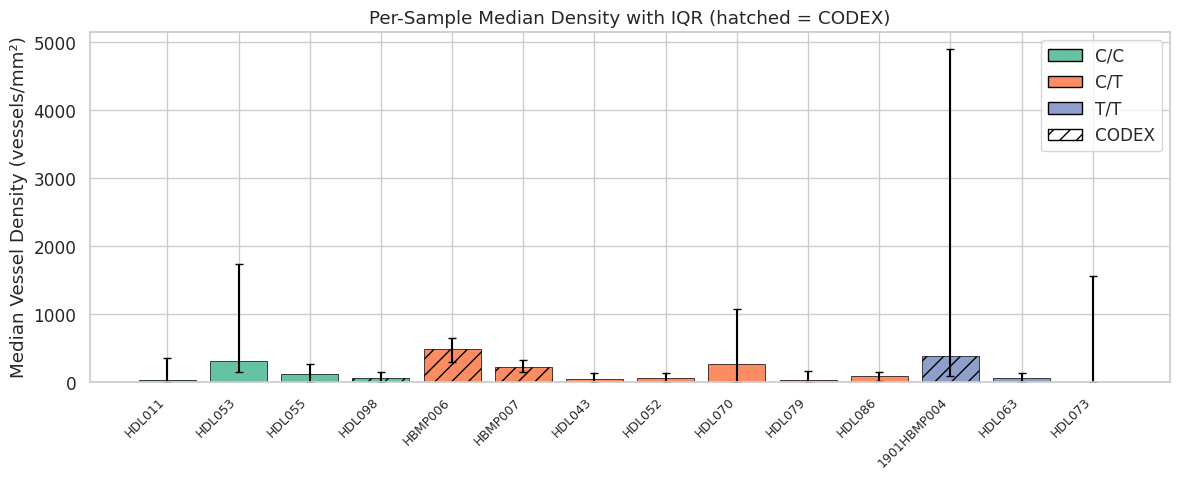

In [6]:
# Per-sample summary: median density and IQR across annotations
sample_stats = fol_per.groupby(['Sample', 'Genotype', 'Platform'], observed=True).agg(
    n_annotations=('Object_ID', 'count'),
    median_density=('Density_per_mm2', 'median'),
    q25=('Density_per_mm2', lambda x: x.quantile(0.25)),
    q75=('Density_per_mm2', lambda x: x.quantile(0.75)),
).reset_index().sort_values(['Genotype', 'Sample'])

fig, ax = plt.subplots(figsize=(12, 5))
x = range(len(sample_stats))
yerr_lo = sample_stats['median_density'] - sample_stats['q25']
yerr_hi = sample_stats['q75'] - sample_stats['median_density']

bars = ax.bar(x, sample_stats['median_density'],
              color=[GENO_PALETTE[g] for g in sample_stats['Genotype']],
              edgecolor='black', linewidth=0.5)
ax.errorbar(x, sample_stats['median_density'],
            yerr=[yerr_lo, yerr_hi], fmt='none', ecolor='black', capsize=3)

# Hatch CODEX samples
for i, (_, row) in enumerate(sample_stats.iterrows()):
    if row['Platform'] == 'CODEX':
        bars[i].set_hatch('//')

ax.set_xticks(x)
ax.set_xticklabels(sample_stats['Sample'], rotation=45, ha='right', fontsize=9)
ax.set_ylabel('Median Vessel Density (vessels/mm²)')
ax.set_title('Per-Sample Median Density with IQR (hatched = CODEX)')

from matplotlib.patches import Patch
legend_elements = [Patch(facecolor=GENO_PALETTE[g], edgecolor='black', label=g)
                   for g in GENO_ORDER]
legend_elements.append(Patch(facecolor='white', edgecolor='black', hatch='//', label='CODEX'))
ax.legend(handles=legend_elements, loc='upper right')

fig.tight_layout()
save_figure(fig, 'H1_follicle_per_sample')
plt.show()

## Figure 4: Gene Dosage Trend (Per-Sample Medians)

Saved: analysis/figures/H1_follicle_dosage_trend.png


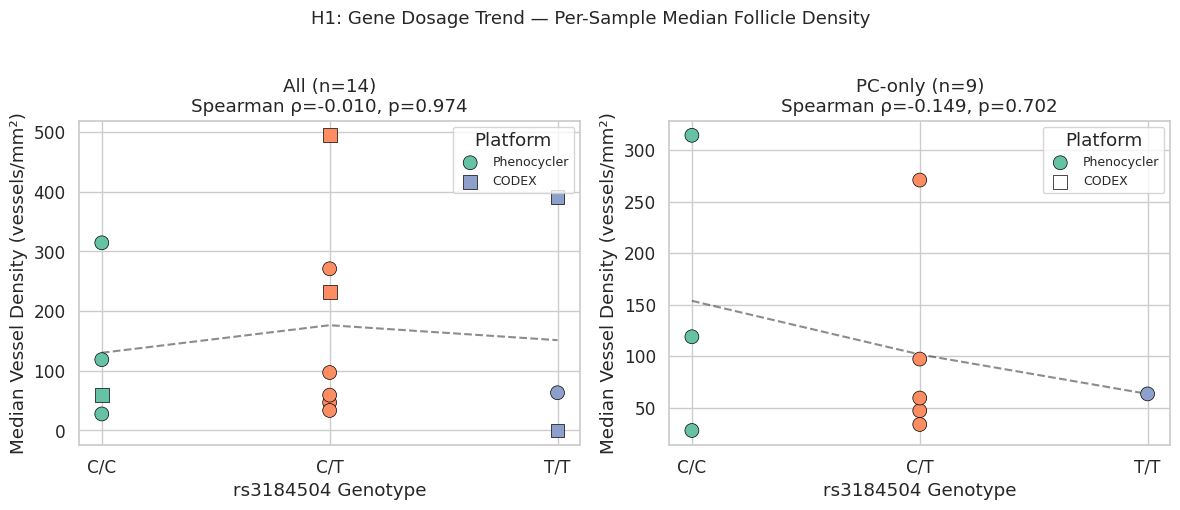

In [7]:
sample_med = fol_per.groupby(['Sample', 'Genotype', 'Platform'], observed=True)['Density_per_mm2'].median().reset_index()
sample_med['Geno_Ordinal'] = sample_med['Genotype'].astype(str).map({'C/C': 0, 'C/T': 1, 'T/T': 2})

rho, sp_p = spearmanr(sample_med['Geno_Ordinal'], sample_med['Density_per_mm2'])

# Phenocycler-only
med_pc = sample_med[sample_med['Platform'] == 'Phenocycler']
rho_pc, sp_p_pc = spearmanr(med_pc['Geno_Ordinal'], med_pc['Density_per_mm2']) if len(med_pc) >= 3 else (np.nan, np.nan)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
markers = {'Phenocycler': 'o', 'CODEX': 's'}

for ax, data, label, r, p in zip(axes,
    [sample_med, med_pc],
    [f'All (n={len(sample_med)})', f'PC-only (n={len(med_pc)})'],
    [rho, rho_pc], [sp_p, sp_p_pc]):

    for plat, mkr in markers.items():
        sub = data[data['Platform'] == plat]
        ax.scatter(sub['Geno_Ordinal'], sub['Density_per_mm2'], marker=mkr, s=100,
                   c=[GENO_PALETTE[g] for g in sub['Genotype']],
                   edgecolors='black', linewidths=0.5, label=plat, zorder=5)

    # Trend line through group means
    means = data.groupby('Geno_Ordinal')['Density_per_mm2'].mean()
    ax.plot(means.index, means.values, 'k--', alpha=0.5, linewidth=1.5)

    ax.set_xticks([0, 1, 2])
    ax.set_xticklabels(GENO_ORDER)
    ax.set_xlabel('rs3184504 Genotype')
    ax.set_ylabel('Median Vessel Density (vessels/mm²)')
    ax.set_title(f'{label}\nSpearman ρ={r:.3f}, p={p:.3f}')
    ax.legend(title='Platform', fontsize=9)

fig.suptitle('H1: Gene Dosage Trend — Per-Sample Median Follicle Density', fontsize=13, y=1.02)
fig.tight_layout()
save_figure(fig, 'H1_follicle_dosage_trend')
plt.show()

## Figure 5: Follicle Vessel Density by Vessel Size

Vessels assigned to follicles (cKDTree) are split into area tertiles.
Per-follicle density is computed separately for each size class.

Vessel area tertile boundaries: [   5.3   28.9   73.2 3495.1]
Total follicle-parented vessels: 23388


/tmp/ipykernel_1592312/1095076323.py:90: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=total_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
/tmp/ipykernel_1592312/1095076323.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
/tmp/ipykernel_1592312/1095076323.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,


/tmp/ipykernel_1592312/1095076323.py:103: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,


Saved: analysis/figures/H1_density_by_vessel_size.png


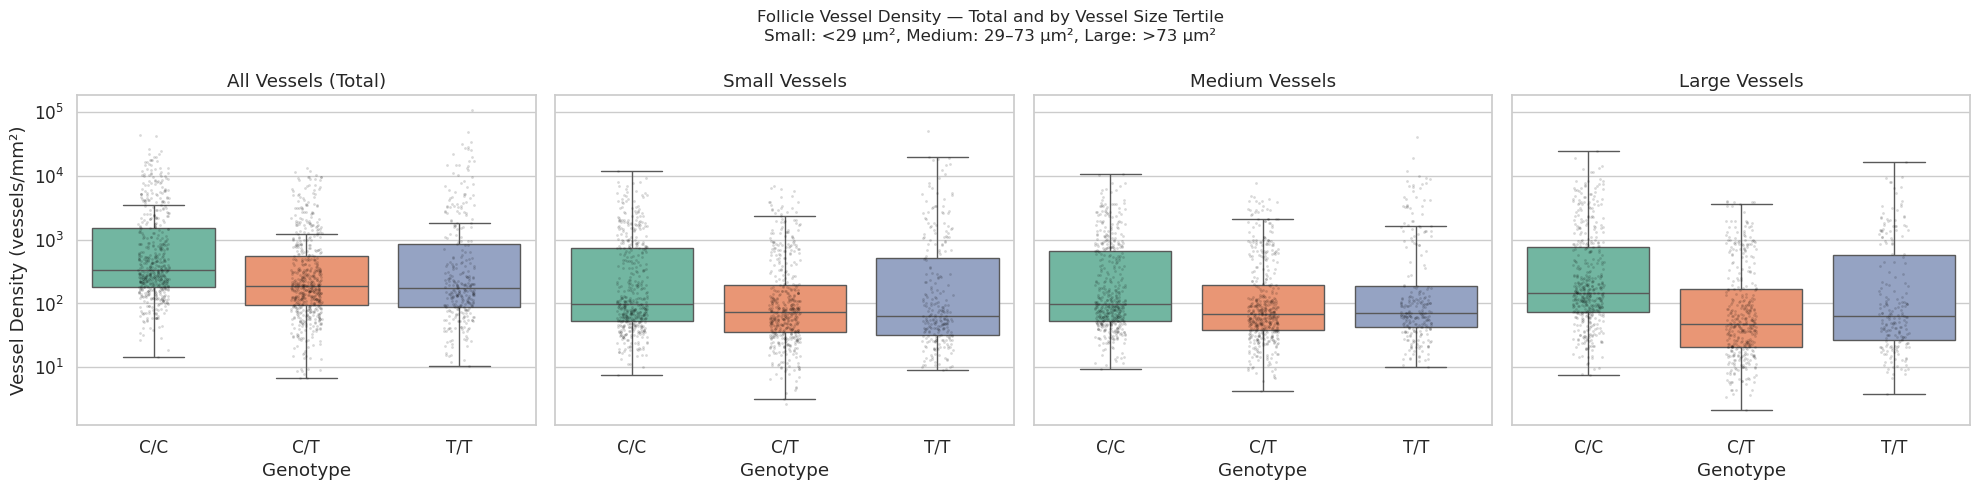


--- LMM: Density ~ Genotype by vessel size class ---
  Small   : Wald p=0.0675
  Medium  : Wald p=0.0754


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with cg
  warnings.warn(


  Large   : Wald p=0.2995


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2206: ConvergenceWarning: MixedLM optimization failed, trying a different optimizer may help.
  warnings.warn(msg, ConvergenceWarning)
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2218: ConvergenceWarning: Gradient optimization failed, |grad| = 6.046530
  warnings.warn(msg, ConvergenceWarning)


In [8]:
# Get all follicle-parented vessels with morphology and annotation assignment
from scipy.spatial import cKDTree

vessel_records = []
for image in df['Image'].unique():
    img_df = df[df['Image'] == image]
    sample = img_df['Sample'].iloc[0]
    genotype = str(img_df['Genotype'].iloc[0])
    platform = 'CODEX' if sample in CODEX_SAMPLES else 'Phenocycler'

    regions = img_df[img_df['Classification'] == 'Follicle'].copy()
    vessels = get_vessels(img_df, region_layer=region_layer)
    fol_vessels = vessels[vessels['Region'] == 'Follicle'].copy()

    if regions.empty or fol_vessels.empty:
        continue

    # Assign vessels to nearest follicle annotation
    reg_coords = regions[['Centroid X µm', 'Centroid Y µm']].values
    tree = cKDTree(reg_coords)
    ves_coords = fol_vessels[['Centroid X µm', 'Centroid Y µm']].values
    _, indices = tree.query(ves_coords)

    reg_areas = regions['Area µm^2'].values
    reg_ids = regions['Object ID'].values

    for j, (_, v) in enumerate(fol_vessels.iterrows()):
        fi = indices[j]
        elongation = v['Max diameter µm'] / v['Min diameter µm'] if v['Min diameter µm'] > 0 else np.nan
        vessel_records.append({
            'Image': image, 'Sample': sample, 'Genotype': genotype, 'Platform': platform,
            'Annotation_ID': reg_ids[fi], 'Annotation_Area_um2': reg_areas[fi],
            'Vessel_Area_um2': v['Area µm^2'],
            'Vessel_Circularity': v['Circularity'],
            'Vessel_Solidity': v['Solidity'],
            'Vessel_Elongation': elongation,
            'Vessel_MaxDiam_um': v['Max diameter µm'],
            'Vessel_MinDiam_um': v['Min diameter µm'],
            'Vessel_Perimeter_um': v['Perimeter µm'],
        })

fol_vessels_df = pd.DataFrame(vessel_records)
fol_vessels_df['Genotype'] = pd.Categorical(fol_vessels_df['Genotype'], categories=GENO_ORDER, ordered=True)

# Area tertiles (computed globally)
fol_vessels_df['Area_Tertile'] = pd.qcut(fol_vessels_df['Vessel_Area_um2'], 3,
                                          labels=['Small', 'Medium', 'Large'])
tertile_edges = pd.qcut(fol_vessels_df['Vessel_Area_um2'], 3, retbins=True)[1]
print(f'Vessel area tertile boundaries: {tertile_edges.round(1)}')
print(f'Total follicle-parented vessels: {len(fol_vessels_df)}')

# Per-annotation density by size tertile
size_density = []
for image in df['Image'].unique():
    img_df = df[df['Image'] == image]
    sample = img_df['Sample'].iloc[0]
    genotype = str(img_df['Genotype'].iloc[0])
    platform = 'CODEX' if sample in CODEX_SAMPLES else 'Phenocycler'

    regions = img_df[img_df['Classification'] == 'Follicle'].copy()
    if regions.empty:
        continue

    img_vessels = fol_vessels_df[fol_vessels_df['Image'] == image]

    for _, reg_row in regions.iterrows():
        rid = reg_row['Object ID']
        rarea_mm2 = reg_row['Area µm^2'] / 1e6
        assigned = img_vessels[img_vessels['Annotation_ID'] == rid]

        for tert in ['Small', 'Medium', 'Large']:
            count = (assigned['Area_Tertile'] == tert).sum()
            size_density.append({
                'Image': image, 'Sample': sample, 'Genotype': genotype,
                'Platform': platform, 'Annotation_ID': rid,
                'Region_Area_mm2': rarea_mm2,
                'Size_Class': tert, 'Vessel_Count': count,
                'Density_per_mm2': count / rarea_mm2,
            })

size_density_df = pd.DataFrame(size_density)
size_density_df['Genotype'] = pd.Categorical(size_density_df['Genotype'], categories=GENO_ORDER, ordered=True)

# --- Figure 5: Total + size-stratified density (log scale) ---
fig, axes = plt.subplots(1, 4, figsize=(20, 5), sharey=True)

# Panel 1: Total (all vessel sizes)
ax = axes[0]
total_plot = fol_per[fol_per['Density_per_mm2'] > 0]
sns.boxplot(data=total_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
            palette=GENO_PALETTE, ax=ax, showfliers=False)
sns.stripplot(data=total_plot, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
              color='black', alpha=0.15, size=2, ax=ax, jitter=True)
ax.set_yscale('log')
ax.set_title('All Vessels (Total)')
ax.set_xlabel('Genotype')
ax.set_ylabel('Vessel Density (vessels/mm²)')

# Panels 2-4: By size tertile
for ax, tert in zip(axes[1:], ['Small', 'Medium', 'Large']):
    sub = size_density_df[(size_density_df['Size_Class'] == tert) &
                          (size_density_df['Density_per_mm2'] > 0)]
    sns.boxplot(data=sub, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
                palette=GENO_PALETTE, ax=ax, showfliers=False)
    sns.stripplot(data=sub, x='Genotype', y='Density_per_mm2', order=GENO_ORDER,
                  color='black', alpha=0.15, size=2, ax=ax, jitter=True)
    ax.set_yscale('log')
    ax.set_title(f'{tert} Vessels')
    ax.set_xlabel('Genotype')
    ax.set_ylabel('')

fig.suptitle(f'Follicle Vessel Density — Total and by Vessel Size Tertile\n'
             f'Small: <{tertile_edges[1]:.0f} µm², '
             f'Medium: {tertile_edges[1]:.0f}–{tertile_edges[2]:.0f} µm², '
             f'Large: >{tertile_edges[2]:.0f} µm²', fontsize=12)
fig.tight_layout()
save_figure(fig, 'H1_density_by_vessel_size')
plt.show()

# LMM for each size class
print('\n--- LMM: Density ~ Genotype by vessel size class ---')
for tert in ['Small', 'Medium', 'Large']:
    sub = size_density_df[size_density_df['Size_Class'] == tert]
    try:
        md = smf.mixedlm('Density_per_mm2 ~ C(Genotype)', sub, groups=sub['Sample']).fit(reml=True)
        wald_p = md.f_test('C(Genotype)[T.C/T] = 0, C(Genotype)[T.T/T] = 0').pvalue
        print(f'  {tert:8s}: Wald p={float(wald_p):.4f}')
    except Exception as e:
        print(f'  {tert:8s}: failed — {e}')

## Figure 6: Vessel Morphology by Genotype (All Regions)

Comprehensive analysis of SmallVessel shape metrics across ALL tissue regions,
not restricted to follicles. Metrics: Area, Circularity, Solidity, Elongation (Max/Min diameter).
LMM with Sample as random intercept for each metric.

Total SmallVessels: 441791 across 14 samples
By region:
Region
RedPulp           321541
Perifollicular     40838
PALS               31800
Follicle           23388
Unassigned         20089
Trabeculae          4135


/tmp/ipykernel_1592312/1863962670.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data_plot, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data_plot, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data_plot, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=data_plot, x='Genotype', y=col, order=GENO_ORDER,


Saved: analysis/figures/H1_vessel_morphology_genotype.png


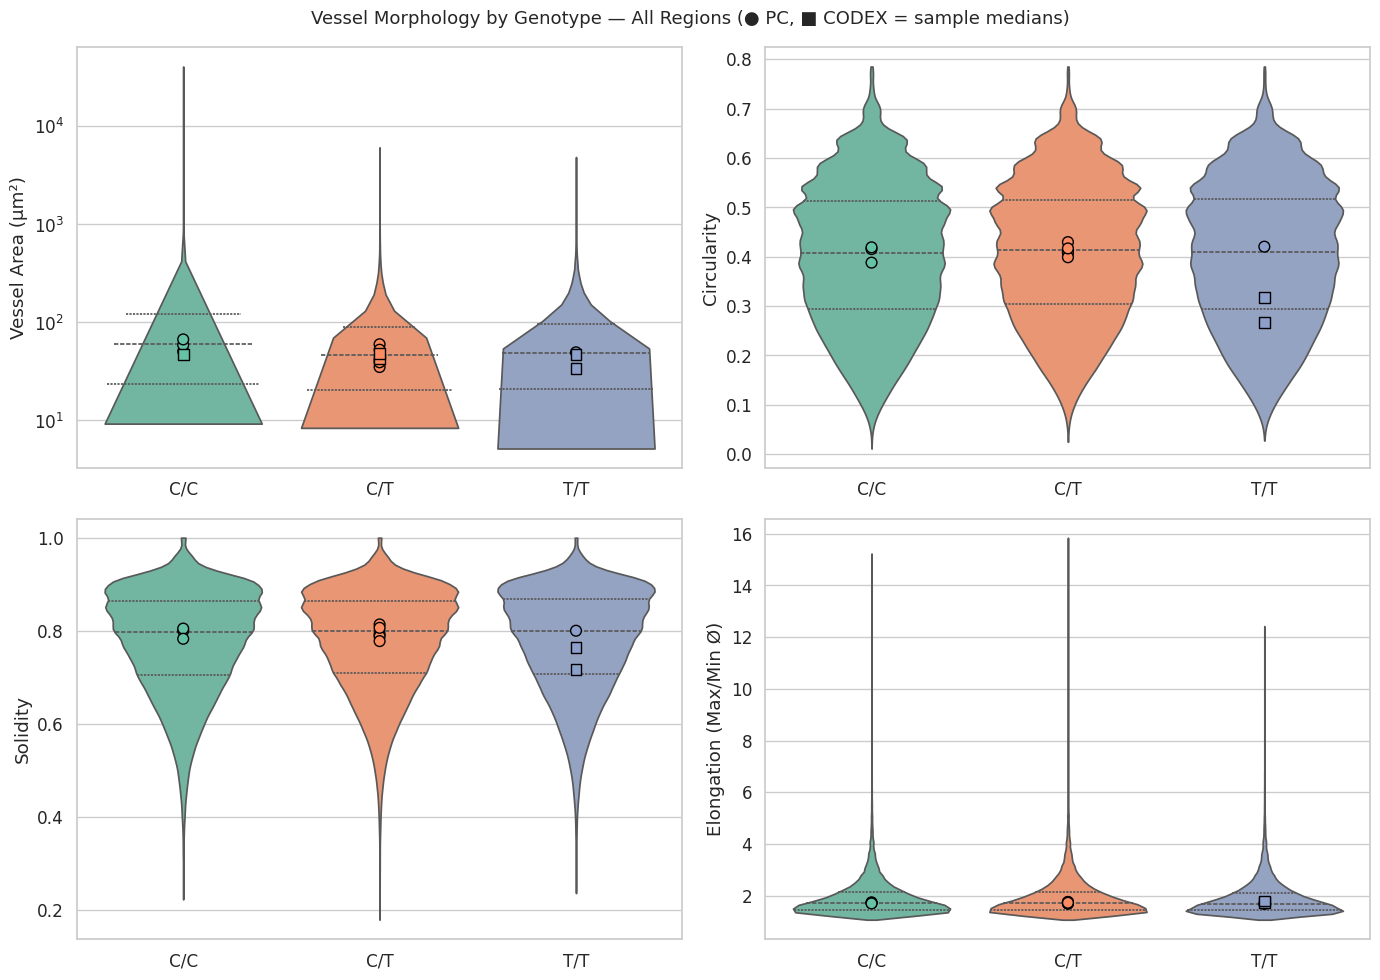

/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


...

/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,
/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


/tmp/ipykernel_1592312/1863962670.py:59: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,


Saved: analysis/figures/H1_vessel_morphology_region_genotype.png


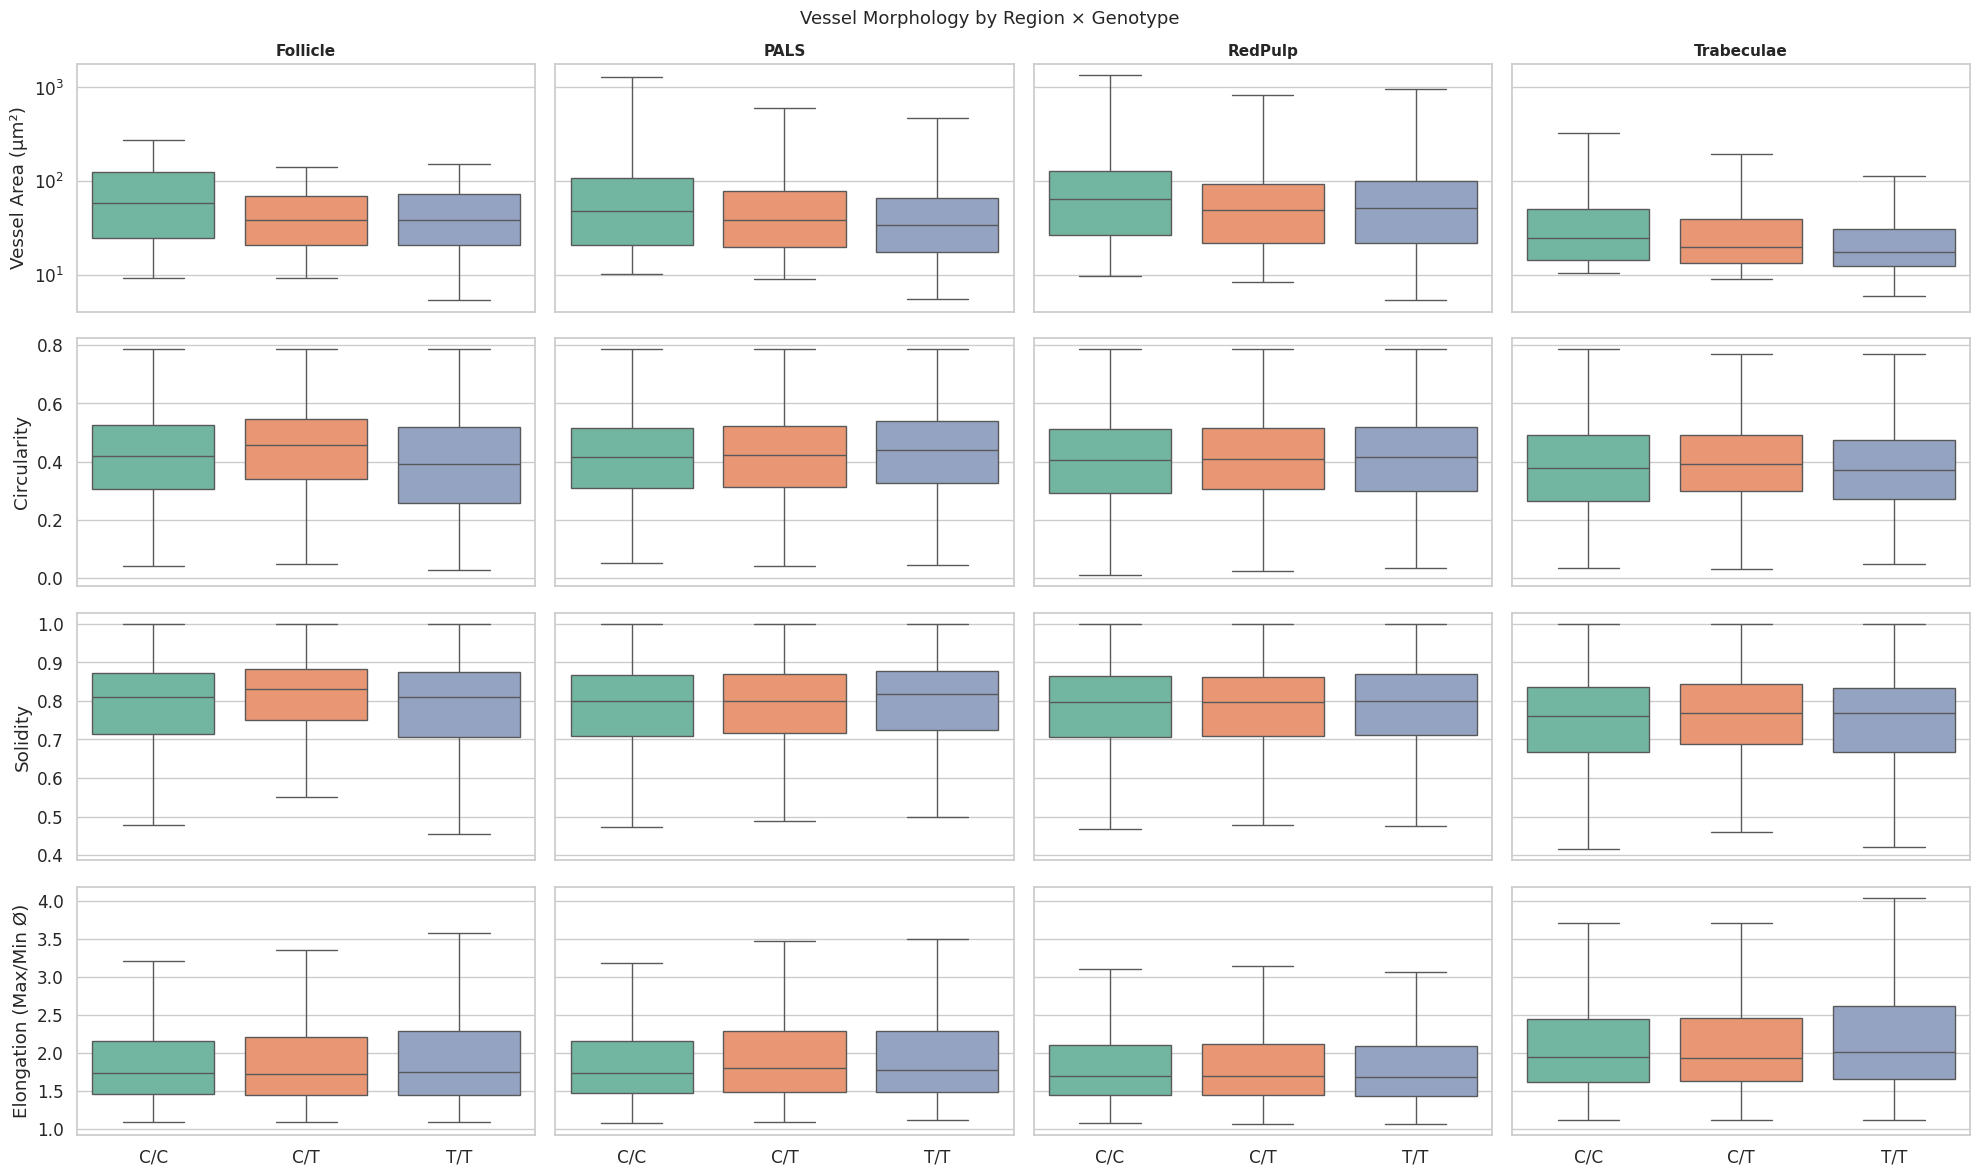


--- LMM: Morphology ~ Genotype (all regions, Sample random intercept) ---


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


  Vessel Area (µm²)             : Wald p=0.0993, ICC=0.009


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2200: ConvergenceWarning: Retrying MixedLM optimization with lbfgs
  warnings.warn(


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


...

/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)
/blue/maigan/smith6jt/miniforge3/envs/xenium_analysis/lib/python3.12/site-packages/statsmodels/regression/mixed_linear_model.py:2237: ConvergenceWarning: The MLE may be on the boundary of the parameter space.
  warnings.warn(msg, ConvergenceWarning)


  Trabeculae   Circularity                   : Wald p=0.0390 *


Saved: analysis/tables/H1_vessel_morphology_tests.csv


,Metric,Wald_p,ICC,n_vessels,n_samples
0,Vessel Area (µm²),0.099307,0.009492,441791,14
1,Circularity,0.034056,0.069031,424637,11
2,Solidity,0.104422,0.033693,424637,11
3,Elongation (Max/Min Ø),0.869763,0.004354,424637,11
4,Vessel Area (µm²) (Follicle),0.064503,NaN,23388,14
5,Circularity (Follicle),0.034381,NaN,22616,11
6,Solidity (Follicle),0.099934,NaN,22616,11
7,Elongation (Max/Min Ø) (Follicle),0.290546,NaN,22616,11
8,Vessel Area (µm²) (PALS),0.109104,NaN,31800,13
9,Circularity (PALS),0.239837,NaN,31178,10


In [9]:
# All SmallVessels across all regions
all_sv = get_vessels(df, region_layer=region_layer)
all_sv['Elongation'] = all_sv['Max diameter µm'] / all_sv['Min diameter µm'].replace(0, np.nan)
all_sv['Platform'] = all_sv['Sample'].apply(
    lambda s: 'CODEX' if s in CODEX_SAMPLES else 'Phenocycler')

print(f'Total SmallVessels: {len(all_sv)} across {all_sv["Sample"].nunique()} samples')
print(f'By region:\n{all_sv["Region"].value_counts().to_string()}')

# --- Morphology metrics ---
morph_metrics = {
    'Area µm^2': 'Vessel Area (µm²)',
    'Circularity': 'Circularity',
    'Solidity': 'Solidity',
    'Elongation': 'Elongation (Max/Min Ø)',
}

# Figure 6a: Violin plots by genotype (all regions pooled)
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
axes = axes.ravel()

for ax, (col, label) in zip(axes, morph_metrics.items()):
    data_plot = all_sv.dropna(subset=[col])
    sns.violinplot(data=data_plot, x='Genotype', y=col, order=GENO_ORDER,
                   palette=GENO_PALETTE, inner='quartile', ax=ax, cut=0)

    # Overlay per-sample medians
    sample_med = data_plot.groupby(['Sample', 'Genotype', 'Platform'], observed=True)[col].median().reset_index()
    for plat, mkr in [('Phenocycler', 'o'), ('CODEX', 's')]:
        sub = sample_med[sample_med['Platform'] == plat]
        x_pos = sub['Genotype'].astype(str).map({g: i for i, g in enumerate(GENO_ORDER)})
        ax.scatter(x_pos, sub[col], marker=mkr, s=60,
                   c=[GENO_PALETTE[g] for g in sub['Genotype']],
                   edgecolors='black', linewidths=1, zorder=10)

    ax.set_ylabel(label)
    ax.set_xlabel('')
    if col == 'Area µm^2':
        ax.set_yscale('log')

fig.suptitle('Vessel Morphology by Genotype — All Regions (● PC, ■ CODEX = sample medians)',
             fontsize=13)
fig.tight_layout()
save_figure(fig, 'H1_vessel_morphology_genotype')
plt.show()

# Figure 6b: Morphology by region × genotype (faceted)
fig, axes = plt.subplots(len(morph_metrics), 4, figsize=(20, 12),
                         sharey='row', sharex=True)
regions_to_plot = ['Follicle', 'PALS', 'RedPulp', 'Trabeculae']

for row, (col, label) in enumerate(morph_metrics.items()):
    for c, region in enumerate(regions_to_plot):
        ax = axes[row, c]
        sub = all_sv[(all_sv['Region'] == region)].dropna(subset=[col])
        if sub.empty:
            ax.set_visible(False)
            continue
        sns.boxplot(data=sub, x='Genotype', y=col, order=GENO_ORDER,
                    palette=GENO_PALETTE, ax=ax, showfliers=False)
        if row == 0:
            ax.set_title(region, fontsize=11, fontweight='bold')
        if c == 0:
            ax.set_ylabel(label)
        else:
            ax.set_ylabel('')
        ax.set_xlabel('')
        if col == 'Area µm^2':
            ax.set_yscale('log')

fig.suptitle('Vessel Morphology by Region × Genotype', fontsize=13)
fig.tight_layout()
save_figure(fig, 'H1_vessel_morphology_region_genotype')
plt.show()

# --- LMM for each morphology metric ---
print('\n--- LMM: Morphology ~ Genotype (all regions, Sample random intercept) ---')
morph_results = []
for col, label in morph_metrics.items():
    sub = all_sv.dropna(subset=[col]).copy()
    try:
        md = smf.mixedlm(f'Q("{col}") ~ C(Genotype)', sub, groups=sub['Sample']).fit(reml=True)
        wald_p = md.f_test('C(Genotype)[T.C/T] = 0, C(Genotype)[T.T/T] = 0').pvalue
        icc = float(md.cov_re.iloc[0, 0]) / (float(md.cov_re.iloc[0, 0]) + float(md.scale))
        print(f'  {label:30s}: Wald p={float(wald_p):.4f}, ICC={icc:.3f}')
        morph_results.append({
            'Metric': label, 'Wald_p': float(wald_p), 'ICC': icc,
            'n_vessels': len(sub), 'n_samples': sub['Sample'].nunique(),
        })
    except Exception as e:
        print(f'  {label:30s}: failed — {e}')

# Also test by region
print('\n--- LMM by region ---')
for region in regions_to_plot:
    for col, label in morph_metrics.items():
        sub = all_sv[(all_sv['Region'] == region)].dropna(subset=[col]).copy()
        if sub['Sample'].nunique() < 3:
            continue
        try:
            md = smf.mixedlm(f'Q("{col}") ~ C(Genotype)', sub, groups=sub['Sample']).fit(reml=True)
            wald_p = md.f_test('C(Genotype)[T.C/T] = 0, C(Genotype)[T.T/T] = 0').pvalue
            morph_results.append({
                'Metric': f'{label} ({region})', 'Wald_p': float(wald_p),
                'n_vessels': len(sub), 'n_samples': sub['Sample'].nunique(),
            })
            if float(wald_p) < 0.1:
                print(f'  {region:12s} {label:30s}: Wald p={float(wald_p):.4f} *')
        except Exception as e:
            pass

morph_results_df = pd.DataFrame(morph_results)
save_table(morph_results_df, 'H1_vessel_morphology_tests')
display(morph_results_df)

## Statistical Tests

**Mixed-effects linear model:** `Density ~ Genotype` with `Sample` as random intercept.
This accounts for the fact that follicles within the same image are not independent.

Also runs the dosage model: `Density ~ Geno_Ordinal` (C/C=0, C/T=1, T/T=2) with `Sample` random intercept.

In [10]:
def run_mixed_model(data, formula, groups_col='Sample'):
    """Fit mixed-effects linear model and return results."""
    md = smf.mixedlm(formula, data, groups=data[groups_col])
    mdf = md.fit(reml=True)
    return mdf

# Prepare ordinal coding
fol_per['Geno_Ordinal'] = fol_per['Genotype'].astype(str).map({'C/C': 0, 'C/T': 1, 'T/T': 2})
fol_pc['Geno_Ordinal'] = fol_pc['Genotype'].astype(str).map({'C/C': 0, 'C/T': 1, 'T/T': 2})

results = []

for data, label in [(fol_per, 'All'), (fol_pc, 'PC-only')]:
    # --- Genotype group model ---
    try:
        geno_model = run_mixed_model(data, 'Density_per_mm2 ~ C(Genotype)')
        print(f'\n{"="*60}')
        print(f'LMM: Density ~ Genotype | {label} (n_follicles={len(data)}, n_samples={data["Sample"].nunique()})')
        print(f'{"="*60}')
        print(geno_model.summary().tables[1].to_string())

        # Extract F-test for genotype effect
        # Use Wald test on genotype coefficients
        wald_p = geno_model.f_test('C(Genotype)[T.C/T] = 0, C(Genotype)[T.T/T] = 0').pvalue
        results.append({
            'Model': f'LMM Genotype ({label})',
            'Test': 'Wald F-test (joint)',
            'p': float(wald_p),
            'n_follicles': len(data),
            'n_samples': data['Sample'].nunique(),
            'ICC': float(geno_model.cov_re.iloc[0, 0]) / (
                float(geno_model.cov_re.iloc[0, 0]) + float(geno_model.scale))
        })
    except Exception as e:
        print(f'LMM Genotype ({label}) failed: {e}')

    # --- Dosage trend model ---
    try:
        dosage_model = run_mixed_model(data, 'Density_per_mm2 ~ Geno_Ordinal')
        print(f'\n--- Dosage model ({label}) ---')
        print(dosage_model.summary().tables[1].to_string())

        coef = dosage_model.params['Geno_Ordinal']
        pval = dosage_model.pvalues['Geno_Ordinal']
        results.append({
            'Model': f'LMM Dosage ({label})',
            'Test': 'Slope (per T allele)',
            'Coefficient': coef,
            'p': pval,
            'n_follicles': len(data),
            'n_samples': data['Sample'].nunique(),
        })
    except Exception as e:
        print(f'LMM Dosage ({label}) failed: {e}')

    # --- Platform confound (All only) ---
    if label == 'All':
        try:
            plat_model = run_mixed_model(data, 'Density_per_mm2 ~ C(Platform)')
            print(f'\n--- Platform model ---')
            print(plat_model.summary().tables[1].to_string())

            plat_p = plat_model.pvalues.get('C(Platform)[T.Phenocycler]',
                     plat_model.pvalues.get('C(Platform)[T.CODEX]', np.nan))
            results.append({
                'Model': 'LMM Platform',
                'Test': 'Platform effect',
                'p': float(plat_p),
                'n_follicles': len(data),
                'n_samples': data['Sample'].nunique(),
            })
        except Exception as e:
            print(f'LMM Platform failed: {e}')

results_df = pd.DataFrame(results)
save_table(results_df, 'H1_statistical_tests')
display(results_df)


LMM: Density ~ Genotype | All (n_follicles=2169, n_samples=14)
                          Coef.  Std.Err.       z  P>|z|     [0.025    0.975]
Intercept               983.282  1052.481   0.934  0.350  -1079.543  3046.107
C(Genotype)[T.C/T]     -541.719  1328.629  -0.408  0.683  -3145.783  2062.345
C(Genotype)[T.T/T]     2596.388  1588.444   1.635  0.102   -516.904  5709.681
Group Var           4044121.414   480.128                                    

--- Dosage model (All) ---
                    Coef. Std.Err.      z  P>|z|     [0.025    0.975]
Intercept         182.574  989.121  0.185  0.854  -1756.068  2121.216
Geno_Ordinal     1199.181  839.506  1.428  0.153   -446.221  2844.582
Group Var     4589265.024  523.124                                   

--- Platform model ---


                                  Coef.  Std.Err.       z  P>|z|     [0.025    0.975]
Intercept                      2747.235  1019.553   2.695  0.007    748.949  4745.522
C(Platform)[T.Phenocycler]    -2082.557  1223.380  -1.702  0.089  -4480.338   315.223
Group Var                   4005846.685   493.948                                    

LMM: Density ~ Genotype | PC-only (n_follicles=1928, n_samples=9)
                         Coef. Std.Err.       z  P>|z|     [0.025    0.975]
Intercept             1192.859  422.625   2.822  0.005    364.529  2021.190
C(Genotype)[T.C/T]    -727.067  540.321  -1.346  0.178  -1786.077   331.943
C(Genotype)[T.T/T]   -1030.228  838.987  -1.228  0.219  -2674.612   614.156
Group Var           501336.073  116.300                                    



--- Dosage model (PC-only) ---
                   Coef. Std.Err.       z  P>|z|     [0.025    0.975]
Intercept       1130.187  364.511   3.101  0.002    415.758  1844.616
Geno_Ordinal    -579.103  362.943  -1.596  0.111  -1290.459   132.253
Group Var     436531.502   94.659                                    
Saved: analysis/tables/H1_statistical_tests.csv


,Model,Test,p,n_follicles,n_samples,ICC,Coefficient
0,LMM Genotype (All),Wald F-test (joint),0.087076,2169,14,0.211128,NaN
1,LMM Dosage (All),Slope (per T allele),0.153167,2169,14,NaN,1199.180549
2,LMM Platform,Platform effect,0.088699,2169,14,NaN,NaN
3,LMM Genotype (PC-only),Wald F-test (joint),0.303325,1928,9,0.066676,NaN
4,LMM Dosage (PC-only),Slope (per T allele),0.110584,1928,9,NaN,-579.102807


In [11]:
# Per-sample summary table
summary = fol_per.groupby(['Sample', 'Genotype', 'Platform'], observed=True).agg(
    n_annotations=('Object_ID', 'count'),
    total_vessels=('Vessel_Count', 'sum'),
    total_area_mm2=('Region_Area_mm2', 'sum'),
    median_density=('Density_per_mm2', 'median'),
    mean_density=('Density_per_mm2', 'mean'),
    std_density=('Density_per_mm2', 'std'),
).reset_index()

# Aggregate density: total vessels / total area
summary['aggregate_density'] = summary['total_vessels'] / summary['total_area_mm2']
summary = summary.sort_values(['Genotype', 'Sample']).round(2)

save_table(summary, 'H1_follicle_density')
display(summary)

Saved: analysis/tables/H1_follicle_density.csv


,Sample,Genotype,Platform,n_annotations,total_vessels,total_area_mm2,median_density,mean_density,std_density,aggregate_density
3,HDL011,C/C,Phenocycler,128,941,4.34,27.69,790.97,2261.10,216.84
6,HDL053,C/C,Phenocycler,406,10223,32.94,314.54,2347.41,5143.21,310.33
7,HDL055,C/C,Phenocycler,220,1201,8.24,118.75,391.10,832.95,145.69
13,HDL098,C/C,CODEX,9,31,0.25,60.00,158.90,285.36,124.74
1,HBMP006,C/T,CODEX,7,622,1.12,494.72,550.57,461.53,552.95
2,HBMP007,C/T,CODEX,8,119,0.42,232.44,266.18,221.20,286.71
4,HDL043,C/T,Phenocycler,176,1131,18.32,46.87,357.37,990.23,61.73
5,HDL052,C/T,Phenocycler,30,148,1.49,59.22,117.70,163.60,99.63
9,HDL070,C/T,Phenocycler,243,2507,8.71,271.01,1284.11,2502.00,287.75
11,HDL079,C/T,Phenocycler,285,1146,8.31,33.54,232.99,704.64,137.89


In [12]:
# ICC: proportion of variance attributable to between-sample differences
print('=' * 60)
print('H1: Per-Follicle Vessel Density — Summary')
print('=' * 60)

# Null model (no fixed effects) to get ICC
null_model = smf.mixedlm('Density_per_mm2 ~ 1', fol_per, groups=fol_per['Sample']).fit(reml=True)
icc = float(null_model.cov_re.iloc[0, 0]) / (float(null_model.cov_re.iloc[0, 0]) + float(null_model.scale))
print(f'\nICC (Sample): {icc:.3f}')
print(f'  → {icc*100:.1f}% of density variance is between samples, {(1-icc)*100:.1f}% within')
print(f'\nTotal follicles: {len(fol_per)}, Samples: {fol_per["Sample"].nunique()}')
print(f'Follicles per sample: {fol_per.groupby("Sample").size().describe().to_string()}')

H1: Per-Follicle Vessel Density — Summary

ICC (Sample): 0.245
  → 24.5% of density variance is between samples, 75.5% within

Total follicles: 2169, Samples: 14
Follicles per sample: count     14.000000
mean     154.928571
std      126.409265
min        7.000000
25%       31.250000
50%      161.500000
75%      237.250000
max      406.000000
